In [1]:
import pandas as pd
import numpy as np
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)
%matplotlib inline

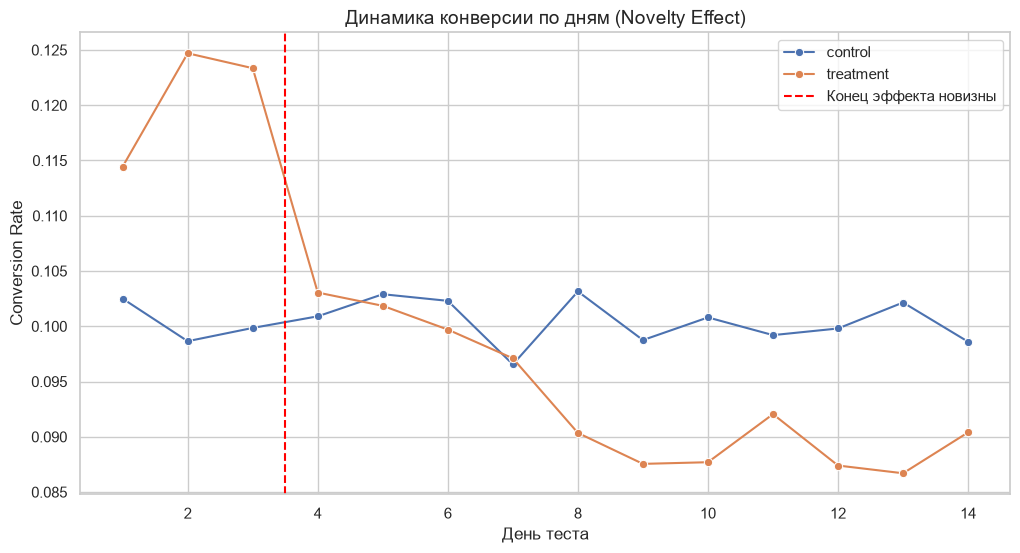

In [2]:
df = pd.read_csv("../data/novelty_peeking.csv")

# Считаем дневную конверсию по группам
daily_cr = df.groupby(["day", "group"])["purchased"].mean().reset_index()

plt.figure(figsize=(12, 6))
sns.lineplot(data=daily_cr, x="day", y="purchased", hue="group", marker="o")
plt.title("Динамика конверсии по дням (Novelty Effect)", fontsize=14)
plt.ylabel("Conversion Rate")
plt.xlabel("День теста")
plt.axvline(x=3.5, color='red', linestyle='--', label='Конец эффекта новизны')
plt.legend()
plt.show()

In [3]:
results = []

# Накапливаем данные день за днем
for day in range(1, 15):
    current_data = df[df["day"] <= day]
    
    control = current_data[current_data["group"] == "control"]
    treatment = current_data[current_data["group"] == "treatment"]
    
    conv_c = control["purchased"].sum()
    conv_t = treatment["purchased"].sum()
    n_c = len(control)
    n_t = len(treatment)
    
    # Z-test
    z_stat, p_value = proportions_ztest([conv_t, conv_c], [n_t, n_c])
    
    # Считаем общую конверсию
    cr_c = conv_c / n_c
    cr_t = conv_t / n_t
    
    results.append({
        "day": day,
        "p_value": p_value,
        "cr_control": cr_c,
        "cr_treatment": cr_t,
        "significant": p_value < 0.05
    })

peek_df = pd.DataFrame(results)
peek_df

,day,p_value,cr_control,cr_treatment,significant
0,1,1.216889e-04,0.102500,0.114450,True
1,2,9.072328e-18,0.100575,0.119575,True
2,3,1.023017e-29,0.100333,0.120833,True
3,4,1.373260e-24,0.100475,0.116388,True
4,5,1.448735e-19,0.100960,0.113480,True
5,6,1.849718e-15,0.101183,0.111183,True
6,7,7.999662e-14,0.100521,0.109171,True
7,8,3.124518e-08,0.100850,0.106819,True
8,9,5.961992e-05,0.100617,0.104678,True
9,10,1.419582e-02,0.100635,0.102980,True


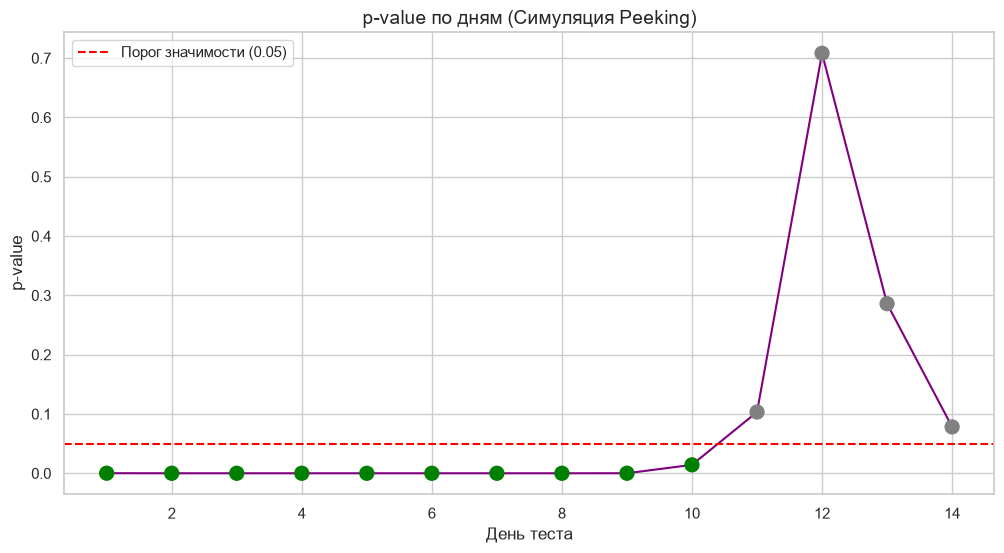

In [4]:
plt.figure(figsize=(12, 6))
plt.plot(peek_df["day"], peek_df["p_value"], marker="o", color="purple")
plt.axhline(y=0.05, color="red", linestyle="--", label="Порог значимости (0.05)")

# Красим точки: зеленые, если значимо
colors = ['green' if p < 0.05 else 'gray' for p in peek_df["p_value"]]
plt.scatter(peek_df["day"], peek_df["p_value"], c=colors, s=100, zorder=5)

plt.title("p-value по дням (Симуляция Peeking)", fontsize=14)
plt.ylabel("p-value")
plt.xlabel("День теста")
plt.legend()
plt.show()

In [5]:
final_data = df

control = final_data[final_data["group"] == "control"]
treatment = final_data[final_data["group"] == "treatment"]

conv_c = control["purchased"].sum()
conv_t = treatment["purchased"].sum()
n_c = len(control)
n_t = len(treatment)

cr_c = conv_c / n_c
cr_t = conv_t / n_t

z_stat, p_value = proportions_ztest([conv_t, conv_c], [n_t, n_c])

print(f"ИТОГ ЗА 14 ДНЕЙ:")
print(f"Control CR: {cr_c:.2%}")
print(f"Treatment CR: {cr_t:.2%}")
print(f"p-value: {p_value:.4f}")

ИТОГ ЗА 14 ДНЕЙ:
Control CR: 10.04%
Treatment CR: 9.90%
p-value: 0.0781


Я вижу, что на 3-й день Treatment показывает значимый рост (+2 п.п., p < 0.05). НО я настоятельно не рекомендую останавливать тест.

Во-первых, у нас может быть эффект новизны (Novelty Effect): пользователи просто пробуют новую яркую кнопку, и через неделю их интерес угаснет. Если мы остановим тест сейчас, мы примем решение на основе временного всплеска.

Во-вторых, мы заранее договорились о длительности теста (14 дней) и размере выборки. Останавливать тест на пике — это Peeking, который в 30% случаев приводит к ложноположительному результату. Давай дождемся конца эксперимента